In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Module imports
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate

import iapws95_light
import iapws95_light.state_rhoT

In [3]:
# Example: compute dict w/ saturation curve data (sat. pressure at 630 K)
saturation_tuple:dict = iapws95_light.state_rhoT.prho_sat(630)

print(f"Saturation pressure (MPa): {saturation_tuple['psat']/1e6}")
print(f"Saturated liquid density (kg/m^3): {saturation_tuple['rho_satl']}")
print(f"Saturated vapour density (kg/m^3): {saturation_tuple['rho_satv']}")

Saturation pressure (MPa): 17.968971393767458
Saturated liquid density (kg/m^3): 544.2474174052742
Saturated vapour density (kg/m^3): 132.83955603693164


Integration check (1/5) de/dv across vapour saturation

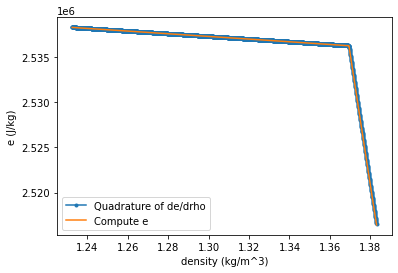

In [4]:
T = 400
# Set sampling range
sat_triple = iapws95_light.state_rhoT.prho_sat(T)
psat = sat_triple["psat"]
rhol = sat_triple["rho_satl"]
rhov = sat_triple["rho_satv"]
rho_range = np.linspace(0.9*rhov, 1.01*rhov, 2001)

# Compute gradient at sampling points
outs = [iapws95_light.float_mix_functions.grad_e_tv(T, 1/rho) for rho in rho_range]
e = [iapws95_light.state_rhoT.u(rho, T) for rho in rho_range]
dedT = np.array([out["dedT"] for out in outs])
dedv = np.array([out["dedv"] for out in outs])
pcheck = np.array([out["p"] for out in outs])
x = np.array([out["x"] for out in outs])

de = scipy.integrate.cumulative_trapezoid(dedv[::-1], 1/rho_range[::-1])
rho_centered = 0.5*(rho_range[1:] + rho_range[:-1])
e = [iapws95_light.state_rhoT.u(rho, T) for rho in rho_centered]
plt.plot(rho_centered, de[::-1] + e[-1], '.-', label="Quadrature of de/drho")
plt.plot(rho_centered, e, label="Compute e")
plt.xlabel("density (kg/m^3)")
plt.ylabel("e (J/kg)")
plt.legend()

Integration check (2/5) de/dv across liquid saturation

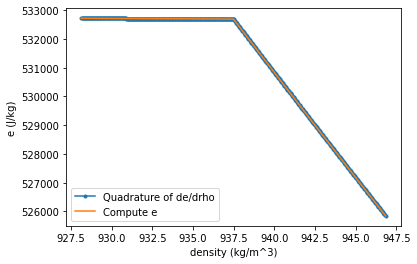

In [5]:
T = 400
# Set sampling range
sat_triple = iapws95_light.state_rhoT.prho_sat(T)
psat = sat_triple["psat"]
rhol = sat_triple["rho_satl"]
rhov = sat_triple["rho_satv"]
rho_range = np.linspace(0.99*rhol, 1.01*rhol, 501)

# Compute gradient at sampling points
outs = [iapws95_light.float_mix_functions.grad_e_tv(T, 1/rho) for rho in rho_range]
e = [iapws95_light.state_rhoT.u(rho, T) for rho in rho_range]
dedT = np.array([out["dedT"] for out in outs])
dedv = np.array([out["dedv"] for out in outs])
pcheck = np.array([out["p"] for out in outs])
x = np.array([out["x"] for out in outs])

de = scipy.integrate.cumulative_trapezoid(dedv, 1/rho_range)
rho_centered = 0.5*(rho_range[1:] + rho_range[:-1])
e = [iapws95_light.state_rhoT.u(rho, T) for rho in rho_centered]

plt.plot(rho_centered, de + e[0], '.-', label="Quadrature of de/drho")
plt.plot(rho_centered, e, label="Compute e")
plt.xlabel("density (kg/m^3)")
plt.ylabel("e (J/kg)")
plt.legend()

Integration check (3/5) de/dv supercritical

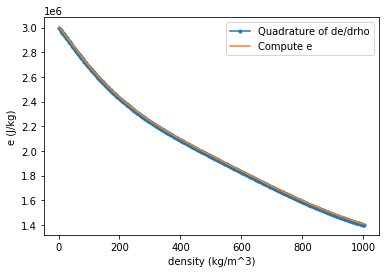

In [6]:
T = 700
# Set sampling range
sat_triple = iapws95_light.state_rhoT.prho_sat(T)
psat = sat_triple["psat"]
rhol = sat_triple["rho_satl"]
rhov = sat_triple["rho_satv"]
rho_range = np.linspace(2, 1002, 501)

# Compute gradient at sampling points
outs = [iapws95_light.float_mix_functions.grad_e_tv(T, 1/rho) for rho in rho_range]
e = [iapws95_light.state_rhoT.u(rho, T) for rho in rho_range]
dedT = np.array([out["dedT"] for out in outs])
dedv = np.array([out["dedv"] for out in outs])
pcheck = np.array([out["p"] for out in outs])
x = np.array([out["x"] for out in outs])

de = scipy.integrate.cumulative_trapezoid(dedv, 1/rho_range)
rho_centered = 0.5*(rho_range[1:] + rho_range[:-1])
e = [iapws95_light.state_rhoT.u(rho, T) for rho in rho_centered]
plt.plot(rho_centered, de + e[0], '.-', label="Quadrature of de/drho")
plt.plot(rho_centered, e, label="Compute e")
plt.xlabel("density (kg/m^3)")
plt.ylabel("e (J/kg)")
plt.legend()

Integration check (4/5) de/dT vapour side

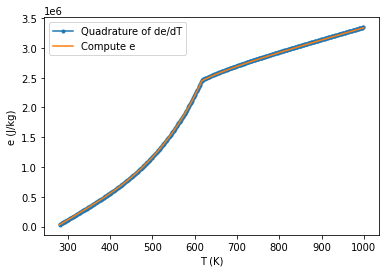

In [7]:
rho = 100
# Set sampling range
T_range = np.linspace(280, 1000, 501)

# Compute gradient at sampling points
outs = [iapws95_light.float_mix_functions.grad_e_tv(T, 1/rho) for T in T_range]
e = [iapws95_light.state_rhoT.u(rho, T) for T in T_range]
dedT = np.array([out["dedT"] for out in outs])
dedv = np.array([out["dedv"] for out in outs])
pcheck = np.array([out["p"] for out in outs])
x = np.array([out["x"] for out in outs])

de = scipy.integrate.cumulative_trapezoid(dedT, T_range)
T_centered = 0.5*(T_range[1:] + T_range[:-1])
e = [iapws95_light.state_rhoT.u(rho, T) for T in T_range]
plt.plot(T_centered, de + e[0], '.-', label="Quadrature of de/dT")
plt.plot(T_range, e, label="Compute e")
plt.xlabel("T (K)")
plt.ylabel("e (J/kg)")
plt.legend()

Integration check (5/5) de/dT vapour side

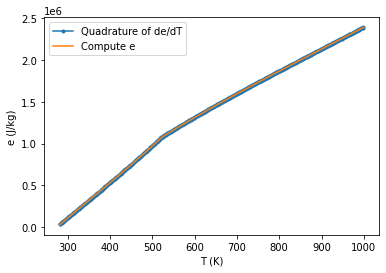

In [8]:
rho = 800
# Set sampling range
T_range = np.linspace(280, 1000, 501)

# Compute gradient at sampling points
outs = [iapws95_light.float_mix_functions.grad_e_tv(T, 1/rho) for T in T_range]
e = [iapws95_light.state_rhoT.u(rho, T) for T in T_range]
dedT = np.array([out["dedT"] for out in outs])
dedv = np.array([out["dedv"] for out in outs])
pcheck = np.array([out["p"] for out in outs])
x = np.array([out["x"] for out in outs])

de = scipy.integrate.cumulative_trapezoid(dedT, T_range)
T_centered = 0.5*(T_range[1:] + T_range[:-1])
e = [iapws95_light.state_rhoT.u(rho, T) for T in T_range]
plt.plot(T_centered, de + e[0], '.-', label="Quadrature of de/dT")
plt.plot(T_range, e, label="Compute e")
plt.xlabel("T (K)")
plt.ylabel("e (J/kg)")
plt.legend()